# Polymorphism
1. The word **Polymorphism** comes from Greek: Poly (many) and Morph (forms).
- Polymorphism is a core concept in Object-Oriented Programming (OOP) that allows objects of different classes to be treated as objects of a common superclass. 
- It provides a way to perform a single action in different forms. Polymorphism is typically achieved through method overriding and interfaces

In programming, it refers to the ability of different objects to respond to the same function call in their own unique way. It allows you to write a single piece of code that can work with many different types of objects.

2. **The Memory Tip: The "Play" Button**
Think of a Play Button.

- If you press Play on a YouTube video, it starts a video.

- If you press Play on a Spotify track, it starts music.

- If you press Play on a Podcast, it starts a voice recording.

- The Action is the same (play()), but the Result depends on what "object" you are interacting with.

3. Polymorphism in Action (Code)
-In Python, we usually see this through Method Overriding (using Inheritance) or Duck Typing.

**Example: The Payment System**
``` Python

class Payment:
    def process(self):
        pass # Template for children

class CreditCard(Payment):
    def process(self):
        print("Validating CVV... Processing Credit Card payment.")

class UPI(Payment):
    def process(self):
        print("Opening scanner... Processing UPI payment.")

# This function demonstrates Polymorphism
def complete_purchase(payment_method):
    # It doesn't care if it's UPI or CreditCard
    # It just knows every Payment object has a .process() method
    payment_method.process()

# Usage
my_card = CreditCard()
my_qr = UPI()

complete_purchase(my_card)
complete_purchase(my_qr)
```
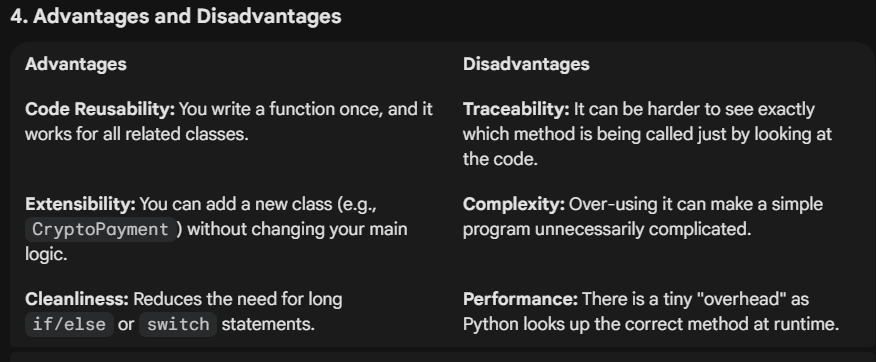

5. **Best Practices:**
Keep Interfaces Consistent: If the parent method is named process(), don't name the child method start_process(). The names must match for polymorphism to work.

- Use Abstract Base Classes (ABC): Use the abc module to ensure that every child must implement the specific polymorphic method.

- Favor "Duck Typing": In Python, we follow the rule: "If it walks like a duck and quacks like a duck, it's a duck." You don't always need strict inheritance; you just need the objects to have the same method names.

## What is Duck typing?

- Duck typing is a programming concept where the suitability of an object for a purpose is determined by its behavior (methods and properties it possesses) rather than its explicit type or class inheritance. 
- The core principle is derived from the "duck test" saying: **"If it walks like a duck and quacks like a duck, then it must be a duck"**. 
- In practice, this means you can use any object in a function or method as long as it supports all the operations (method calls, attribute access) expected by that function or method, regardless of its actual type. 
### 
**Key Concepts:**
1. Focus on Behavior: The primary concern is "what an object can do" rather than "what an object is".
2. Dynamic Type Checking: Duck typing is primarily used in dynamically typed languages (like Python, Ruby, JavaScript) where type checks happen at runtime, not compile time.
3. Implicit Interfaces: Instead of explicit interfaces (like in Java or C#), an object's compliance with a "protocol" (a set of expected methods) is implied by its use in context. 

**Example in Python**
Consider a function perform_action that needs an object capable of walk() and quack() methods. You can pass instances of completely unrelated classes, Duck and Person, as long as both implement these methods. 

``` python
class Duck:
    def walk(self):
        print("Quack, quack, I'm walking.")
    def quack(self):
        print("Quack, quack!")

class Person:
    def walk(self):
        print("I'm walking like a duck.")
    def quack(self):
        print("I'm quacking like a duck!")

def perform_action(entity):
    entity.walk()
    entity.quack()

# Both objects work because they have the required methods
duck_instance = Duck()
person_instance = Person()

perform_action(duck_instance) 
# Output: Quack, quack, I'm walking.
#         Quack, quack!

perform_action(person_instance)
# Output: I'm walking like a duck.
#         I'm quacking like a duck!

```

In this example, the perform_action function doesn't check if the object is an instance of the Duck class. It simply assumes that whatever object it receives will have walk() and quack() methods and tries to call them. If the object doesn't have the expected methods, a runtime error (specifically an AttributeError in Python) will occur. 

In [6]:
# Example of implicit interface
# No formal 'interface' or 'implements' keyword needed

class Dog:
    def speak(self):
        print("Woof!")

class Cat:
    def speak(self):
        print("Meow!")

# A function that implicitly expects any object with a 'speak' method
def animal_sound(animal):
    animal.speak()

# Both Dog and Cat objects work because they both satisfy the implicit 'speak' interface
animal_sound(Dog())
animal_sound(Cat())

'''
The animal_sound function doesn't care about the type of animal it receives; 
it only cares that the object has a callable speak method. 
If an object without a speak method were passed in, a runtime error (specifically an AttributeError) would occur
'''


Woof!
Meow!


"\nThe animal_sound function doesn't care about the type of animal it receives; \nit only cares that the object has a callable speak method. \nIf an object without a speak method were passed in, a runtime error (specifically an AttributeError) would occur\n"

In [ ]:
### Polymorphissm with Functions and MEthods  Basically a method overridding thing
## base class
class Shape:
    def area(self):
        return "The area of the figure"
    
## Derived class 1
class Rectangle(Shape):
    def __init__(self,width,height):
        self.width=width
        self.height=height
        self.name = "Rectangle"
    def area(self):
        return self.width * self.height
    
##DErived class 2
class Circle(Shape):
    def __init__(self,radius):
        self.radius=radius
        self.name = "Circle"
    def area(self):
        return round(3.14*self.radius *self.radius,2)


class Square(Shape):
    def __init__(self,side):
        self.side = side 
        self.name = "Square"
    def area(self):
        return self.side ** 2

## Fucntion that demonstrates polymorphism

def print_area(shape):
    print(f"The area of {shape.name} : {shape.area()}")


rectangle=Rectangle(4,5)
circle=Circle(3)
square = Square(9)
print_area(rectangle)
print_area(circle)
print_area(square)

The area of Rectangle : 20
The area of Circle : 28.26
The area of Square : 81


# Polymorphism with Abstract Base Classes 
- Abstract Base Classes (ABCs) are used to define common methods for a group of related objects. They can enforce that derived classes implement particular methods, promoting consistency across different implementations.

- When you combine Polymorphism with Abstract Base Classes (ABC), you are essentially creating a "Strict Contract."

- In regular polymorphism, a child can override a parent. With ABCs, a child MUST override the parent. This ensures that your polymorphic code never breaks because a method is missing.

### **The Breakdown: The "Strict Contract"** 
1. The Abstract Class (The Blueprint): Defines what methods are required but doesn't provide the code.

2. The Concrete Classes (The Builders): Must provide the specific code for those required methods.

3. The Polymorphic Function (The User): Calls the method on any object, knowing for a fact it exists.

**Why is this better?**
-If you tried to create a new class called Triangle(Shape) but forgot to define def area(self):, Python would throw an error the moment you tried to create the object:

- TypeError: Can't instantiate abstract class Triangle with abstract method area

- This "fails fast," preventing bugs before your program even runs!

**Best Practices for ABC Polymorphism**
Minimalist Blueprints: Only put methods in the ABC that are truly common to every child.

* Documentation: Use the docstring in the @abstractmethod to tell other programmers exactly what the child method should return.

* Type Hinting: In your polymorphic functions, hint the abstract class: def print_area(shape_obj: Shape): — This tells your editor to expect any "Shape" child.

In [22]:
from abc import ABC, abstractmethod
import math

# 1. THE ABSTRACT BASE CLASS (The Contract)
class Shape(ABC):
    @abstractmethod
    def area(self):
        """This method MUST be implemented by any shape.""" # this needs to be empty!!
        pass

# 2. CONCRETE CLASSES (Implementing the contract)
class Square(Shape):
    def __init__(self, side):
        self.side = side

    def area(self):
        return self.side ** 2

class Circle(Shape):
    def __init__(self, radius):
        self.radius = radius

    def area(self):
        return math.pi * (self.radius ** 2)
    
class Rectangle(Shape):
    def __init__(self, length,breadth):
        self.length = length
        self.breadth = breadth
    def area(self):
        return self.length * self.breadth

# 3. POLYMORPHISM (The flexible function)
def print_area(shape_obj):
    # This function is confident that 'area()' exists because of the ABC
    print(f"The area is: {shape_obj.area():.2f}")

# --- Execution ---
shapes = [Square(4), Circle(5),Rectangle(4,5)]

for s in shapes:
    print_area(s)

The area is: 16.00
The area is: 78.54
The area is: 20.00


In [ ]:
# Lets Understand this with GOD
from abc import ABC,abstractmethod
class God(ABC):
    @abstractmethod
    def avtaram(self):
        """this is implemented based on yuga and situation"""
        pass

class TrethaYuga(God):
    def __init__(self,yuga):
        self.yuga = yuga
    def avtaram(self):
        return f"I am Rama, lets fight for Rightful in this {self.yuga} yuga"

class DwaparaYuga(God):
    def __init__(self,yuga):
        self.yuga = yuga
    def avtaram(self):
        return f"I am Krishna, lets fight for Dharma/Truth in this {self.yuga} yuga"

class Kaliyuga(God):
    def __init__(self,yuga):
        self.yuga = yuga
    def avtaram(self):
        return f"I am the Kali Avtar lets reset the Cycle of life as people lost their mind in this {self.yuga} yuga!!!"

def saviour(yugas):
    return f"Avtar for this yuga says:'{yugas.avtaram()}' "

# k = DwaparaYuga("Dwaparayugam")
# saviour(k)

k = [TrethaYuga("Threthayugam"),DwaparaYuga("Dwaparayugam"),Kaliyuga("Kaliyugam")]
for i in k:
    print(saviour(i))
    print('---'*8)


Avtar for this yuga says:'I am Rama, lets fight for Rightful in this Threthayugam yuga' 
------------------------
Avtar for this yuga says:'I am Krishna, lets fight for Dharma/Truth in this Dwaparayugam yuga' 
------------------------
Avtar for this yuga says:'I am the Kali Avtar lets reset the Cycle of life as people lost their mind in this Kaliyugam yuga!!!' 
------------------------


In Python, the two primary types of polymorphism are Duck Typing (Dynamic Polymorphism) and Method Overriding (Inheritance-based Polymorphism). Because Python is a dynamically typed language, it does not support traditional compile-time polymorphism like Method Overloading (having multiple methods with the same name but different arguments) out of the box. Here is how the two native types work in Python:

## 1. Duck Typing (Dynamic Polymorphism)

Duck typing is based on the philosophy: "If it walks like a duck and quacks like a duck, it's a duck." Python doesn’t care about the specific class type of an object; it only cares whether the object has the required methods or behaviors.
- How it works: Different independent classes implement a method with the same name. You can pass any of these objects into a single function, and Python will execute the method dynamically.
- Code Example:
```python
class Duck:
    def quack(self):
    return *Quack, quack!*

class Person:
    def quack(self):
    return *I am immitating a duck!*

# This function doesn't care about the class type, only the 'quack' method

def make_it_quack(thing):
    print(thing.quack())

make_it_quack(Duck())    # Outputs: Quack, quack! 
make_it_quack(Person())  # Outputs: I am immitating a duck! Use code with caution.
```

## 2. Method Overriding (Inheritance Polymorphism)

Method overriding occurs when a child class provides a specific implementation of a method that is already defined in its parent class.
- How it works: The child class overrides the parent's behavior. When you call the method on a child object, Python executes the child's version rather than the parent's.
- Code Example:
```python
class Animal:
    def speak(self):
    return *Some generic sound*

class Dog(Animal):
    def speak(self):
    return *Woof!*

class Cat(Animal):
    def speak(self):
    return *Meow!*

animals = [Dog(), Cat()]
for animal in animals:
    print(animal.speak())  # Outputs *Woof!* then *Meow!*
```

What about Method Overloading?

If you come from languages like Java or C++, you might look for Method Overloading (same method name, different signatures). If you define two methods with the same name in Python, the last one defined will completely overwrite the previous ones.
To achieve overloading-like behavior in Python, you can use:
- Default arguments: def my_func(a, b=None):
- Variable arguments: def my_func(*args, **kwargs):
- The @singledispatch decorator: Found in the built-in functools module for true function overloading based on argument types.